GEE Exploration in Junyper Notebooks

In [1]:
# import the libraries that we need
import ee
import matplotlib.pyplot as plt
from datetime import datetime

## initialize the Earth Engine module
## i have already authenticated GEE on this machine, you will have to do that
## for each machine you run things on
ee.Initialize()

In [2]:
## load the shapefile (this is saved as an asset in GEE)
## can change it out for a few different ones if we are interested in different areas

roi = ee.FeatureCollection('projects/ee-tlasharr/assets/UT_Paunsaugunt')
# roi = ee.FeatureCollection('projects/ee-tlasharr/assets/NV_Izzenhood')
# roi = ee.FeatureCollection('projects/ee-tlasharr/assets/WY_Sublette')

## we will need to reproject the shapefile so that it matches the VI from GEE

# so first, we will get the projection and print it out
roi_projection = roi.first().geometry().projection()
print('Projection of the shapefile:', roi_projection.getInfo())

# then we can load MODIS NDVI dataset (MOD13Q1)
modis_ndvi = ee.ImageCollection('MODIS/006/MOD13Q1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('NDVI')

# and then load VIIRS Vegetation Indices dataset (VNP13A1)
viirs_ndvi = ee.ImageCollection('NASA/VIIRS/002/VNP13A1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('NDVI')

viirs_evi = ee.ImageCollection('NASA/VIIRS/002/VNP13A1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('EVI')

# we will need to deal with snow cover, so next, we load MODIS snow cover dataset
modis_snow = ee.ImageCollection('MODIS/006/MOD10A1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('NDSI_Snow_Cover')

## now we can reproject the shapefile
modis_projection = modis_ndvi.first().projection() ## this is the projection of the first image of the modis ndvi data
target_crs = modis_projection.crs() ## this is the crs from the modis.projection object
target_crs_scale = modis_projection.nominalScale() ## this is the scale (confused on what this is need to figure this out)

## this is a function to reproject it
def reproject_feature(feature):
    return feature.setGeometry(feature.geometry().transform(target_crs, target_crs_scale))

## this is running the function, so now "reprojected_roi" is the new object we care about
reprojected_roi = roi.map(reproject_feature)

Projection of the shapefile: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}


c:\Users\tlasharr\AppData\Local\Programs\Python\Python312\Lib\site-packages\ee\deprecation.py:207: DeprecationWarning: 

Attention required for MODIS/006/MOD13Q1! You are using a deprecated asset.
To ensure continued functionality, please update it.
Learn more: https://developers.google.com/earth-engine/datasets/catalog/MODIS_006_MOD13Q1

  warnings.warn(warning, category=DeprecationWarning)
c:\Users\tlasharr\AppData\Local\Programs\Python\Python312\Lib\site-packages\ee\deprecation.py:207: DeprecationWarning: 

Attention required for MODIS/006/MOD10A1! You are using a deprecated asset.
To ensure continued functionality, please update it.
Learn more: https://developers.google.com/earth-engine/datasets/catalog/MODIS_006_MOD10A1

  warnings.warn(warning, category=DeprecationWarning)


In [3]:
## function to mask snow cover, this is a step to help us understand how snow plays into the curves
## especially important for desert systems, right now I set it to mask cells with more than 35% snow cover
def apply_snow_mask(image, snow_image):
    snow_mask = ee.Algorithms.If(
        snow_image,
        snow_image.lte(35),  ## if the snow cover is less than or equal to 35%
        ee.Image(1)          ## default mask (all values included if no corresponding snow image)
    )
    return image.updateMask(snow_mask)

## clip MODIS NDVI dataset to the reprojected shapefile
clipped_modis_ndvi = modis_ndvi.map(lambda image: image.clip(reprojected_roi))

## clip VIIRS NDVI and EVI datasets
clipped_viirs_ndvi = viirs_ndvi.map(lambda image: image.clip(reprojected_roi))
clipped_viirs_evi = viirs_evi.map(lambda image: image.clip(reprojected_roi))

## apply the snow mask to MODIS NDVI
modis_ndvi_without_snow = clipped_modis_ndvi.map(
    lambda image: apply_snow_mask(image, modis_snow.filterDate(image.date(), image.date().advance(1, 'day')).first())
)

# apply snow mask to VIIRS NDVI and EVI
# for now we are using the MODIS snow cover data
# because I can't figure out how to get the VIIRS snow layer in GEE
viirs_ndvi_without_snow = clipped_viirs_ndvi.map(
    lambda image: apply_snow_mask(image, modis_snow.filterDate(image.date(), image.date().advance(1, 'day')).first())
)

viirs_evi_without_snow = clipped_viirs_evi.map(
    lambda image: apply_snow_mask(image, modis_snow.filterDate(image.date(), image.date().advance(1, 'day')).first())
)

## now, this is a function so that we can get the actual data and plot it
## this function will get the average values for the region of interest for each time step

def get_time_series(image_collection, region, scale, band):
    def calculate_mean(image):
        mean_value = image.reduceRegion(reducer=ee.Reducer.mean(), geometry=region, scale=scale)
        time = ee.Date(image.get('system:time_start')).millis()
        return ee.Feature(None, mean_value.set('system:time_start', time))

    time_series = image_collection.map(calculate_mean)
    time_series_list = time_series.getInfo()['features']

    ## extract time and values, and filter out None values
    dates = []
    values = []
    for feature in time_series_list:
        date = feature['properties'].get('system:time_start')
        value = feature['properties'].get(band)

        if date is not None and value is not None:
            dates.append(date)
            values.append(value)

    return dates, values

## convert dates to readable format
def convert_dates(dates):
    return [datetime.utcfromtimestamp(date / 1000) for date in dates]

## get time series data for MODIS and VIIRS NDVI and EVI
modis_dates, modis_values = get_time_series(clipped_modis_ndvi, reprojected_roi,
                                            scale=int(target_crs_scale.getInfo()), band='NDVI')

viirs_ndvi_dates, viirs_ndvi_values = get_time_series(clipped_viirs_ndvi, reprojected_roi,
                                                      scale=int(target_crs_scale.getInfo()), band='NDVI')

viirs_evi_dates, viirs_evi_values  = get_time_series(clipped_viirs_evi, reprojected_roi,
                                                     scale=int(target_crs_scale.getInfo()), band='EVI')

## now with snow masked
modis_dates2, modis_values2 = get_time_series(modis_ndvi_without_snow, reprojected_roi,
                                            scale=int(target_crs_scale.getInfo()), band='NDVI')

viirs_ndvi_dates2, viirs_ndvi_values2 = get_time_series(viirs_ndvi_without_snow, reprojected_roi,
                                                      scale=int(target_crs_scale.getInfo()), band='NDVI')

viirs_evi_dates2, viirs_evi_values2  = get_time_series(viirs_evi_without_snow, reprojected_roi,
                                                     scale=int(target_crs_scale.getInfo()), band='EVI')

## convert dates to readable format
modis_dates = convert_dates(modis_dates)
viirs_ndvi_dates = convert_dates(viirs_ndvi_dates)
viirs_evi_dates = convert_dates(viirs_evi_dates)

## might be able to 
modis_dates2 = convert_dates(modis_dates2)
viirs_ndvi_dates2 = convert_dates(viirs_ndvi_dates2)
viirs_evi_dates2 = convert_dates(viirs_evi_dates2)

C:\Users\tlasharr\AppData\Local\Temp\ipykernel_16252\3692390844.py:61: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  return [datetime.utcfromtimestamp(date / 1000) for date in dates]


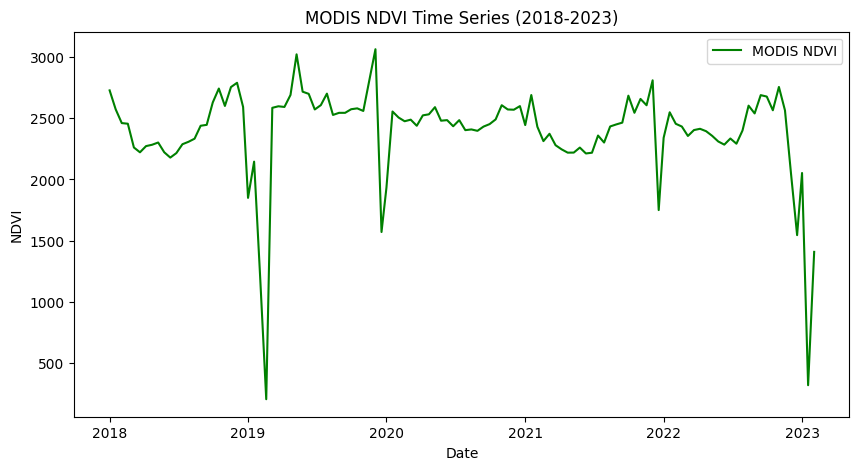

In [4]:

## plot MODIS NDVI time series
plt.figure(figsize=(10, 5))
plt.plot(modis_dates, modis_values, label='MODIS NDVI', color='green')
plt.title('MODIS NDVI Time Series (2018-2023)')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.legend()
plt.show()

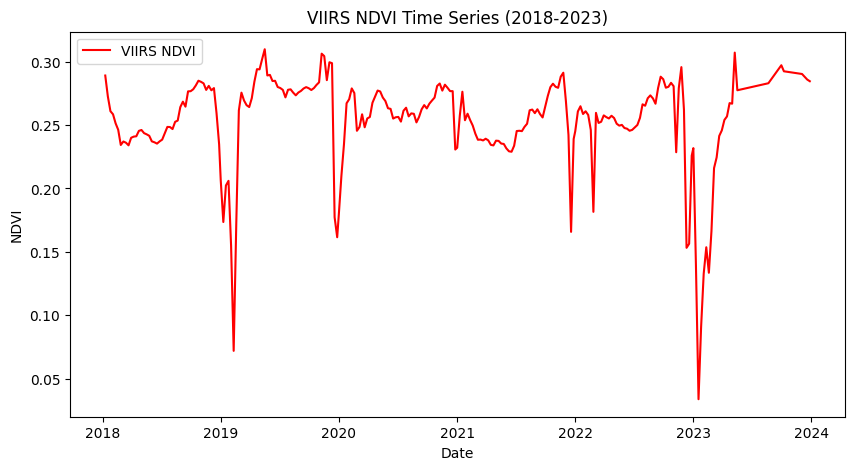

In [5]:
## plot VIIRS NDVI time series
plt.figure(figsize=(10, 5))
plt.plot(viirs_ndvi_dates, viirs_ndvi_values, label='VIIRS NDVI', color='red')
plt.title('VIIRS NDVI Time Series (2018-2023)')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.legend()
plt.show()

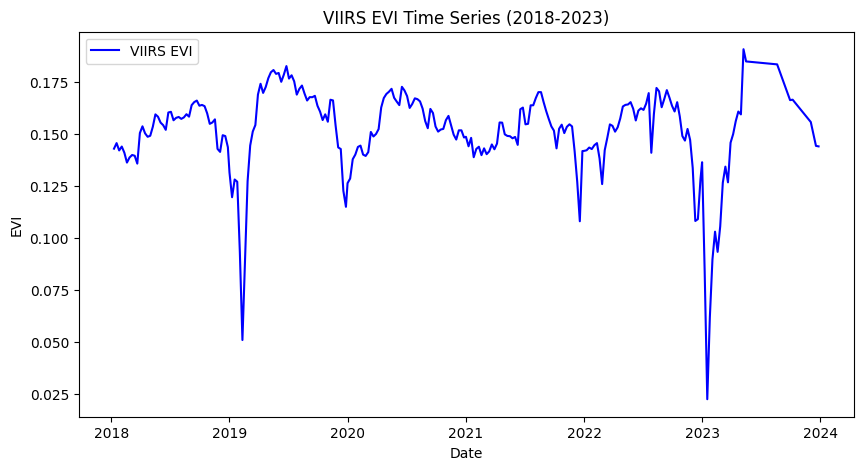

In [6]:
## plot VIIRS EVI time series
plt.figure(figsize=(10, 5))
plt.plot(viirs_evi_dates, viirs_evi_values, label='VIIRS EVI', color='blue')
plt.title('VIIRS EVI Time Series (2018-2023)')
plt.xlabel('Date')
plt.ylabel('EVI')
plt.legend()
plt.show()


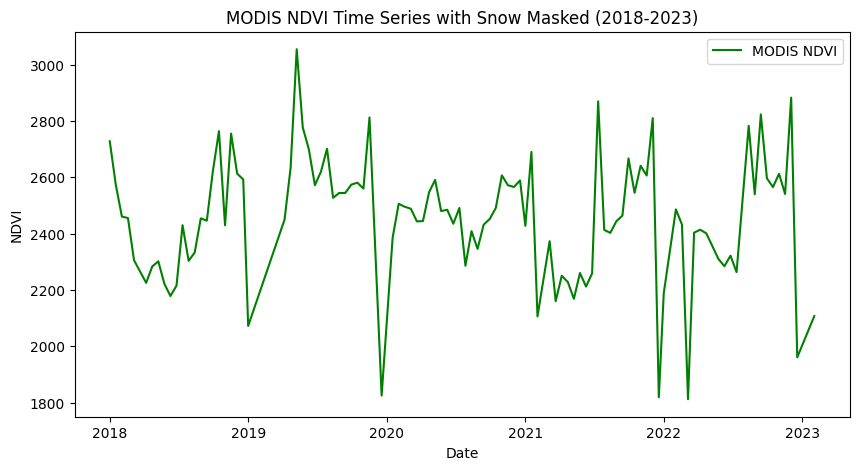

In [7]:

## plot MODIS NDVI time series (with snow masked)
plt.figure(figsize=(10, 5))
plt.plot(modis_dates2, modis_values2, label='MODIS NDVI', color='green')
plt.title('MODIS NDVI Time Series with Snow Masked (2018-2023)')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.legend()
plt.show()

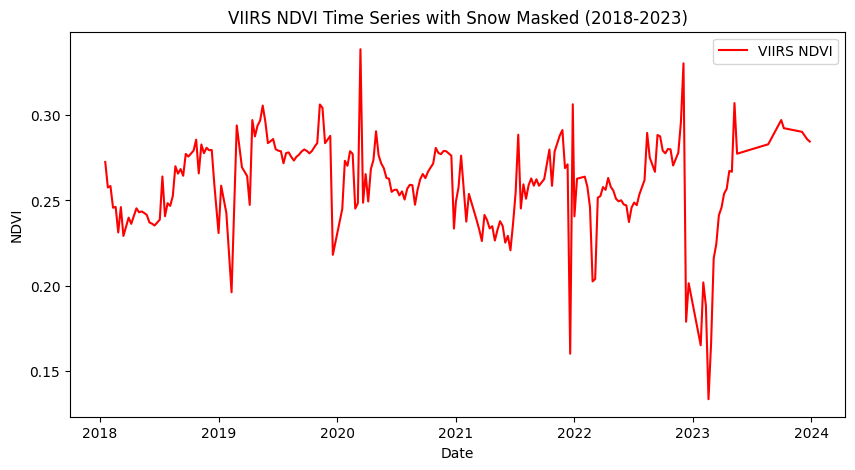

In [8]:
## plot VIIRS NDVI time series (with snow masked)
plt.figure(figsize=(10, 5))
plt.plot(viirs_ndvi_dates2, viirs_ndvi_values2, label='VIIRS NDVI', color='red')
plt.title('VIIRS NDVI Time Series with Snow Masked (2018-2023)')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.legend()
plt.show()

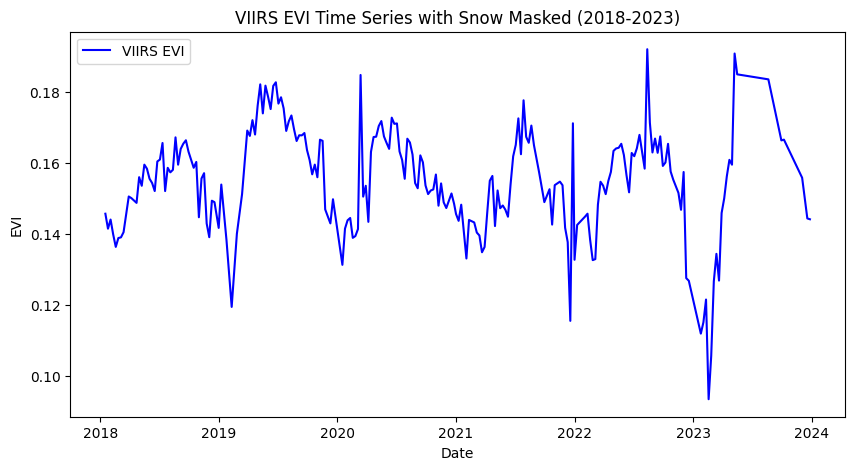

In [9]:
## plot VIIRS EVI time series (with snow masked)
plt.figure(figsize=(10, 5))
plt.plot(viirs_evi_dates2, viirs_evi_values2, label='VIIRS EVI', color='blue')
plt.title('VIIRS EVI Time Series with Snow Masked (2018-2023)')
plt.xlabel('Date')
plt.ylabel('EVI')
plt.legend()
plt.show()